# Optimizing the Structure of Water

:::{div}
:class: colab-badge
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/blinkletter/UsingPsi4v2/blob/main/temp/02-optimization.ipynb)
:::


In [1]:
####################################################
### Import Libraries and set up global variables ###
####################################################

from pathlib import Path
import sys

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Psi4 cannot be installed with pip. On Colab we first install conda
# (condacolab), which RESTARTS the session. After the restart, run
# this cell again and Psi4 will be installed with conda.
try:
    import psi4
except ImportError:
    if IN_COLAB:
        !pip -q install condacolab
        import condacolab
        condacolab.install()
        !mamba install -q -y -c conda-forge psi4
    import psi4

try:
    import py3Dmol
except ImportError:
    !pip -q install py3Dmol
    import py3Dmol

# Standard imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Style sheets and helper functions from the book's GitHub repository
if IN_COLAB:
    if not Path("styles/tufte.mplstyle").exists():
        !wget -q -N -P styles https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/styles/tufte.mplstyle
        !wget -q -N https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/psi4_helpers.py
    plt.style.use("styles/tufte.mplstyle")
    nproc = 2          # Colab gives you 2 cores
else:
    sys.path.insert(0, "..")                    # psi4_helpers.py is one folder up
    plt.style.use("../styles/tufte.mplstyle")
    nproc = 4          # house limit: 4 threads

import psi4_helpers as ph

# All Psi4 .out and .log files go into the output folder
output_dir = Path("output")
output_dir.mkdir(exist_ok=True)

# Resources: house limits are 4 threads and 4 GB
psi4.set_num_threads(nproc)
_ = psi4.set_memory("2 GB")


  Threads set to 4 by Python driver.



  Memory set to   1.863 GiB by Python driver.


The energy of a molecule depends on where its nuclei are. A **geometry optimization** moves the atoms downhill on this **potential energy surface** until it reaches a minimum: the structure where all the forces on the atoms are zero.

## What You Will Learn
- What a **potential energy surface** looks like for one coordinate.
- How to run `psi4.optimize()` and follow its progress step by step.
- What the **convergence criteria** mean and how to tighten them.
- Why the coordinate system used by the optimizer matters.

In [2]:
psi4.set_output_file("output/02-optimization.out", False);
psi4.set_options({"basis": "6-31g*", "scf_type": "pk"})

```{note} Why HF/6-31G* here?
:class: dropdown
`hf` with `6-31g*` (also written 6-31G(d)) is a classic low-cost combination. The `*` adds *d* functions on oxygen, which let the electron density bend away from the atom; without them the H–O–H angle of water comes out several degrees too large. HF/6-31G* geometries are usually within about 0.02 Å and 2° of experiment for simple organic molecules.

*Alternatives:* `b3lyp/6-31g*` costs a little more and is usually closer to experiment for bond lengths; `hf/cc-pvdz` is similar in cost and quality to HF/6-31G*. The next notebook compares several choices.
```

## 1. A Slice Through the Potential Energy Surface

First we keep the angle fixed at 104.5° and calculate the energy for a series of O–H bond lengths (both bonds stretched together). This is a **rigid scan**: nothing else is allowed to relax.

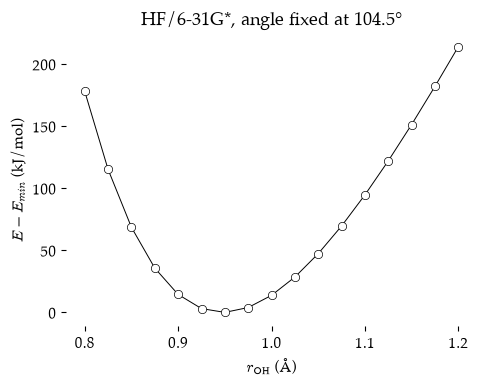

Lowest point of this scan: r = 0.950 Å


In [3]:
distances = np.arange(0.80, 1.21, 0.025)
energies = []

for r in distances:
    mol = psi4.geometry(f"""
    0 1
    O
    H 1 {r}
    H 1 {r} 2 104.5
    """)
    energies.append(psi4.energy("hf", molecule=mol))

energies = np.array(energies)
rel = (energies - energies.min()) * psi4.constants.hartree2kJmol

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(5,4))
ax.plot(distances, rel, color="black", linewidth=0.7, marker="o",
        markerfacecolor="white", markeredgecolor="black", markeredgewidth=0.5)
ax.set_xlabel(r"$r_{\mathrm{OH}}$ (Å)")
ax.set_ylabel(r"$E - E_{min}$ (kJ/mol)")
ax.set_title("HF/6-31G*, angle fixed at 104.5°")
plt.show()

print(f"Lowest point of this scan: r = {distances[energies.argmin()]:.3f} Å")

The curve has a single minimum. An optimizer does the same job without scanning: at each step it calculates the **gradient** (the slope, which is the negative of the force on each atom) and uses it to decide which way to move all the atoms at once.

## 2. Optimizing from a Poor Starting Structure

We start from a deliberately bad structure (long bonds and a wide angle) so that the optimizer has some work to do.

```{note} Psi4 settings in this cell
:class: dropdown
`psi4.optimize("hf", ..., return_history=True)`
: Runs the optimization with the *optking* optimizer and also returns a dictionary with the energy, gradient and coordinates of every step. `return_wfn=True` also returns the final wavefunction (orbitals, properties), which we use in later notebooks.

`g_convergence` (not set, so the default `"qchem"` is used)
: The test for "close enough to the minimum". The default stops when the largest force is below $3\times10^{-4}$ hartree/bohr **and** either the energy change is below $10^{-6}$ hartree or the largest step is below $1.2\times10^{-3}$ bohr. This is good enough for structures and energies.
: *Alternatives:* `"gau"` (the *Gaussian* program's criteria, similar), `"gau_tight"` or `"gau_verytight"` (use before a frequency calculation on a floppy molecule or for very accurate structures), `"cfour"`, `"nwchem_loose"`.

`geom_maxiter` (default 50)
: The maximum number of optimization steps. Water converges in a handful; raise it for floppy molecules.
```

In [4]:
water = psi4.geometry("""
0 1
O
H 1 1.10
H 1 1.10 2 125.0
""")

print(f"Start:  r = {ph.bond_length(water, 0, 1):.4f} Å   angle = {ph.bond_angle(water, 1, 0, 2):.2f}°")

E_opt, wfn, history = psi4.optimize("hf", molecule=water, return_wfn=True, return_history=True)

print(f"Final:  r = {ph.bond_length(water, 0, 1):.4f} Å   angle = {ph.bond_angle(water, 1, 0, 2):.2f}°")
print(f"Final energy = {E_opt:.8f} hartree after {len(history['energy'])} steps")

Start:  r = 1.1000 Å   angle = 125.00°


Optimizer: Optimization complete!
Final:  r = 0.9473 Å   angle = 105.48°
Final energy = -76.01074650 hartree after 7 steps


The molecule object `water` has been **updated in place**: it now holds the optimized structure. Let us plot the energy at each step.

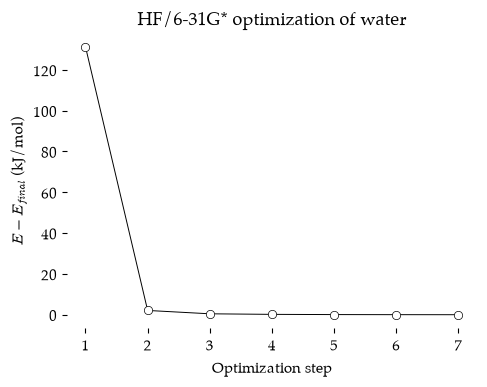

In [5]:
ph.plot_history(history, "HF/6-31G* optimization of water")

The first step drops the energy by over 100 kJ/mol; the last few steps change it by much less than 1 kJ/mol. The optimizer stops when the changes become negligible, not when they are exactly zero.

## 3. Watching the Optimization

The history contains the coordinates of each step (in bohr). We can turn them into a short animation.

In [6]:
def history_to_xyz(mol, history):
    """Build a multi-frame XYZ string from an optimization history."""
    symbols = [mol.symbol(i) for i in range(mol.natom())]
    frames = []
    for step, coords in enumerate(history["coordinates"]):
        xyz = np.asarray(coords) * psi4.constants.bohr2angstroms
        lines = [str(len(symbols)), f"step {step + 1}"]
        lines += [f"{s} {x:12.6f} {y:12.6f} {z:12.6f}" for s, (x, y, z) in zip(symbols, xyz)]
        frames.append("\n".join(lines))
    return "\n".join(frames) + "\n"

view = py3Dmol.view(width=400, height=300)
view.addModelsAsFrames(history_to_xyz(water, history), "xyz")
view.setStyle({"stick": {}, "sphere": {"scale": 0.25}})
view.setBackgroundColor("#f2f2f2")
view.zoomTo()
view.animate({"loop": "forward", "interval": 600})
view.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

## 4. Tighter Convergence

How much does the result change if we demand a much tighter convergence? We restart from the same poor structure.

In [7]:
rows = []
for crit in ["qchem", "gau", "gau_tight", "gau_verytight"]:
    mol = psi4.geometry("""
    0 1
    O
    H 1 1.10
    H 1 1.10 2 125.0
    """)
    psi4.set_options({"g_convergence": crit})
    E, hist = psi4.optimize("hf", molecule=mol, return_history=True)
    rows.append({"g_convergence": crit, "steps": len(hist["energy"]),
                 "r(O-H) Å": ph.bond_length(mol, 0, 1),
                 "angle °": ph.bond_angle(mol, 1, 0, 2),
                 "E (hartree)": E})

psi4.set_options({"g_convergence": "qchem"})      # back to the default
pd.DataFrame(rows).round({"r(O-H) Å": 6, "angle °": 4, "E (hartree)": 9})

Optimizer: Optimization complete!


Optimizer: Optimization complete!


Optimizer: Optimization complete!


Optimizer: Optimization complete!


,g_convergence,steps,r(O-H) Å,angle °,E (hartree)
0,qchem,7,0.947330,105.4804,-76.010746
1,gau,7,0.947330,105.4804,-76.010746
2,gau_tight,8,0.947319,105.4999,-76.010747
3,gau_verytight,8,0.947319,105.4999,-76.010747


Tighter criteria cost a few extra steps but change the bond length only in the fourth or fifth decimal place. For a small, stiff molecule like water the default is fine. Tight criteria matter for **floppy** molecules (rotating methyl groups, weak complexes such as the water dimer) and before **frequency** calculations.

## 5. Which Coordinates Does the Optimizer Use?

*optking* normally works in **internal coordinates** (bond lengths, angles, dihedrals) because chemical motions are simple in them. We can force it to work in Cartesian coordinates instead.

```{note} Psi4 setting: `opt_coordinates`
:class: dropdown
`"redundant"` or `"internal"` (default)
: Bond stretches, bends and torsions. Efficient for most molecules.

`"cartesian"`
: Plain $x, y, z$ steps. Usually needs more steps, but can help when internal coordinates break down (for example, near linear arrangements).

`"both"`
: Uses both sets together; sometimes helpful for difficult cases such as weakly bound complexes.
```

In [8]:
rows = []
for coords in ["redundant", "cartesian"]:
    mol = psi4.geometry("""
    0 1
    O
    H 1 1.10
    H 1 1.10 2 125.0
    """)
    psi4.set_options({"opt_coordinates": coords})
    E, hist = psi4.optimize("hf", molecule=mol, return_history=True)
    rows.append({"opt_coordinates": coords, "steps": len(hist["energy"]), "E (hartree)": E})

psi4.set_options({"opt_coordinates": "redundant"})
pd.DataFrame(rows)

Optimizer: Optimization complete!


Optimizer: Optimization complete!


,opt_coordinates,steps,E (hartree)
0,redundant,7,-76.010746
1,cartesian,8,-76.010746


Both reach the same energy. For water the difference in step count is small; for larger molecules internal coordinates usually win clearly.

```{important} An optimized structure is not proven to be a minimum
An optimizer stops wherever the forces vanish. That can be a **minimum** or a **saddle point** (a transition state). For example, if we started from an exactly linear water molecule, symmetry would keep it linear and the optimizer would happily "converge" there. The way to check is a **frequency calculation**: a minimum has no imaginary frequencies. We do that in the *Vibrations* notebook.
```

## Summary
- An optimization follows the gradient downhill on the potential energy surface.
- `return_history=True` lets us plot and animate the progress.
- The default convergence criteria are adequate for structures; tighten them before frequencies on floppy molecules.
- A converged optimization still needs a frequency check to confirm a minimum.